In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Titanic dataset
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (891, 15)


In [2]:
# Display first 5 rows
print("First 5 Rows of Dataset:")
display(df.head())

# Display last 5 rows
print("Last 5 Rows of Dataset:")
display(df.tail())

First 5 Rows of Dataset:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


Last 5 Rows of Dataset:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [3]:
# Display dataset information
print("Dataset Information:")
df.info()

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display number of rows and columns
print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB

Column Names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked'

In [4]:
# Identify numerical columns
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns
categorical_columns = df.select_dtypes(
    include=["object", "bool"]
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']

Categorical Columns:
['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [5]:
# Calculate statistical summary
print("Basic Statistical Summary:")
display(df.describe())

Basic Statistical Summary:


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
# Count missing values in each column
missing_count = df.isnull().sum()

# Calculate missing value percentage
missing_percentage = (missing_count / len(df)) * 100

# Create missing value report
missing_report = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percentage
})

print("Missing Values Report:")
display(missing_report)

Missing Values Report:


,Missing Values,Missing Percentage
survived,0,0.000000
pclass,0,0.000000
sex,0,0.000000
age,177,19.865320
sibsp,0,0.000000
parch,0,0.000000
fare,0,0.000000
embarked,2,0.224467
class,0,0.000000
who,0,0.000000


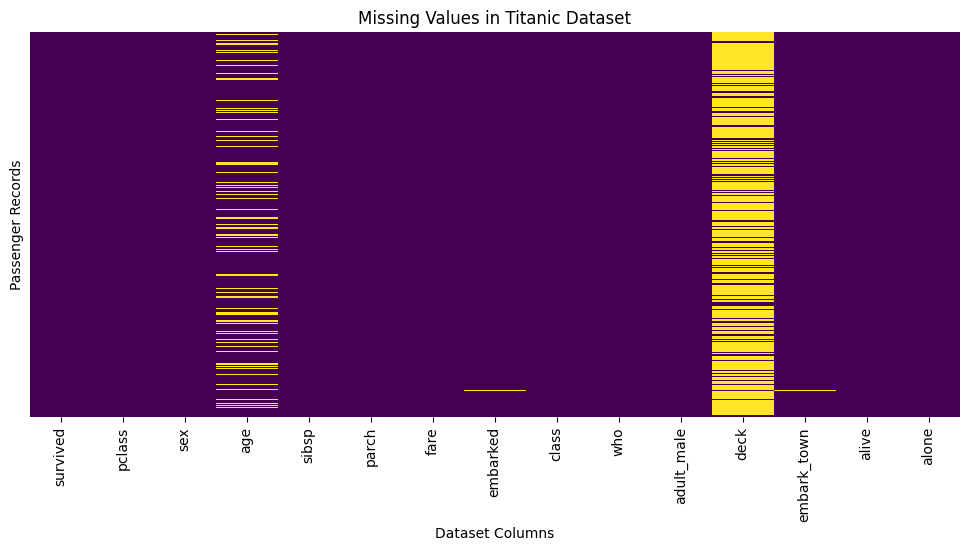

In [7]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values in Titanic Dataset")
plt.xlabel("Dataset Columns")
plt.ylabel("Passenger Records")

plt.show()

In [8]:
# Create backup of original dataset
df_original = df.copy()

# Create a separate dataset for cleaning
df_clean = df.copy()

print("Original dataset backup created successfully!")
print("Original Dataset Shape:", df_original.shape)
print("Cleaning Dataset Shape:", df_clean.shape)

Original dataset backup created successfully!
Original Dataset Shape: (891, 15)
Cleaning Dataset Shape: (891, 15)


In [9]:
# Find median age
age_median = df_clean["age"].median()

print("Median Age:", age_median)

# Fill missing age values
df_clean["age"] = df_clean["age"].fillna(age_median)

# Check missing values after filling
print("\nMissing Age Values After Cleaning:")
print(df_clean["age"].isnull().sum())

Median Age: 28.0

Missing Age Values After Cleaning:
0


In [10]:
# Find mode of embarked column
embarked_mode = df_clean["embarked"].mode()[0]

print("Mode of Embarked:", embarked_mode)

# Fill missing values
df_clean["embarked"] = df_clean["embarked"].fillna(embarked_mode)

# Check missing values
print("\nMissing Embarked Values After Cleaning:")
print(df_clean["embarked"].isnull().sum())

Mode of Embarked: S

Missing Embarked Values After Cleaning:
0


In [11]:
# Remove deck column
df_clean = df_clean.drop(columns=["deck"])

print("Deck column removed successfully!")

# Check updated dataset shape
print("Updated Dataset Shape:", df_clean.shape)

# Display remaining columns
print("\nRemaining Columns:")
print(df_clean.columns.tolist())

Deck column removed successfully!
Updated Dataset Shape: (891, 14)

Remaining Columns:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive', 'alone']


In [12]:
# Remove redundant columns
columns_to_drop = [
    "class",
    "who",
    "adult_male",
    "embark_town",
    "alive"
]

df_clean = df_clean.drop(columns=columns_to_drop)

print("Redundant columns removed successfully!")

print("\nUpdated Dataset Shape:")
print(df_clean.shape)

print("\nRemaining Columns:")
print(df_clean.columns.tolist())

Redundant columns removed successfully!

Updated Dataset Shape:
(891, 9)

Remaining Columns:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'alone']


In [13]:
# Check missing values in cleaned dataset
print("Missing Values in Each Column:")
print(df_clean.isnull().sum())

# Calculate total missing values
print("\nTotal Missing Values:")
print(df_clean.isnull().sum().sum())

Missing Values in Each Column:
survived    0
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
alone       0
dtype: int64

Total Missing Values:
0


In [14]:
# Count duplicate rows
duplicate_count = df_clean.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_count)

# Display duplicate records
display(df_clean[df_clean.duplicated(keep=False)].head(10))

Number of Duplicate Rows: 116


,survived,pclass,sex,age,sibsp,parch,fare,embarked,alone
4,0,3,male,35.0,0,0,8.0500,S,True
23,1,1,male,28.0,0,0,35.5000,S,True
26,0,3,male,28.0,0,0,7.2250,C,True
28,1,3,female,28.0,0,0,7.8792,Q,True
29,0,3,male,28.0,0,0,7.8958,S,True
32,1,3,female,28.0,0,0,7.7500,Q,True
37,0,3,male,21.0,0,0,8.0500,S,True
42,0,3,male,28.0,0,0,7.8958,C,True
45,0,3,male,28.0,0,0,8.0500,S,True
46,0,3,male,28.0,1,0,15.5000,Q,False


In [15]:
# Display duplicate records for inspection
duplicates = df_clean[
    df_clean.duplicated(keep=False)
]

display(duplicates.head(20))

print("Total duplicate records:", len(duplicates))

,survived,pclass,sex,age,sibsp,parch,fare,embarked,alone
4,0,3,male,35.0,0,0,8.0500,S,True
23,1,1,male,28.0,0,0,35.5000,S,True
26,0,3,male,28.0,0,0,7.2250,C,True
28,1,3,female,28.0,0,0,7.8792,Q,True
29,0,3,male,28.0,0,0,7.8958,S,True
32,1,3,female,28.0,0,0,7.7500,Q,True
37,0,3,male,21.0,0,0,8.0500,S,True
42,0,3,male,28.0,0,0,7.8958,C,True
45,0,3,male,28.0,0,0,8.0500,S,True
46,0,3,male,28.0,1,0,15.5000,Q,False


Total duplicate records: 174


In [16]:
# Check unique categorical values

print("Gender Categories:")
print(df_clean["sex"].unique())

print("\nEmbarked Categories:")
print(df_clean["embarked"].unique())

Gender Categories:
['male' 'female']

Embarked Categories:
['S' 'C' 'Q']


In [17]:
# Summary statistics of numerical columns
print("Numerical Summary Statistics:")
display(df_clean.describe())

# Frequency count of passenger gender
print("\nPassenger Gender Distribution:")
print(df_clean["sex"].value_counts())

# Frequency count of passenger class
print("\nPassenger Class Distribution:")
print(df_clean["pclass"].value_counts())

Numerical Summary Statistics:


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208
std,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Passenger Gender Distribution:
sex
male      577
female    314
Name: count, dtype: int64

Passenger Class Distribution:
pclass
3    491
1    216
2    184
Name: count, dtype: int64


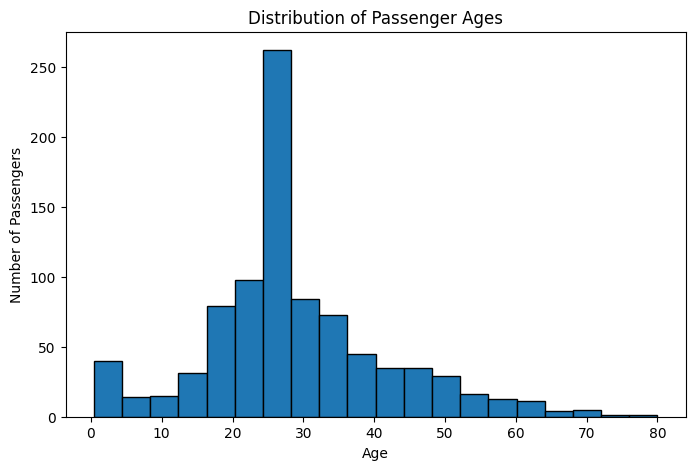

In [18]:
plt.figure(figsize=(8, 5))

plt.hist(
    df_clean["age"],
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

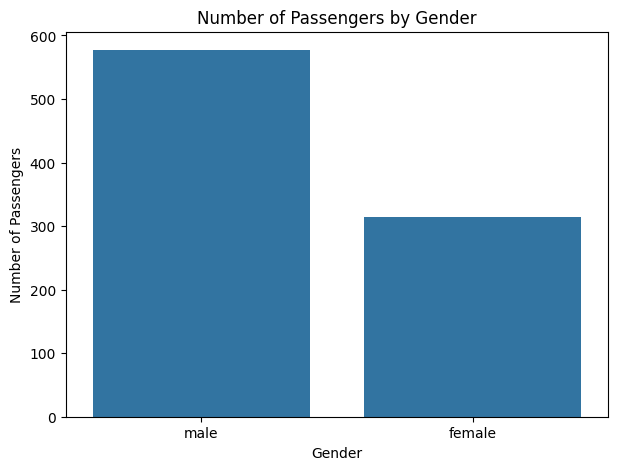

In [19]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="sex")

plt.title("Number of Passengers by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()

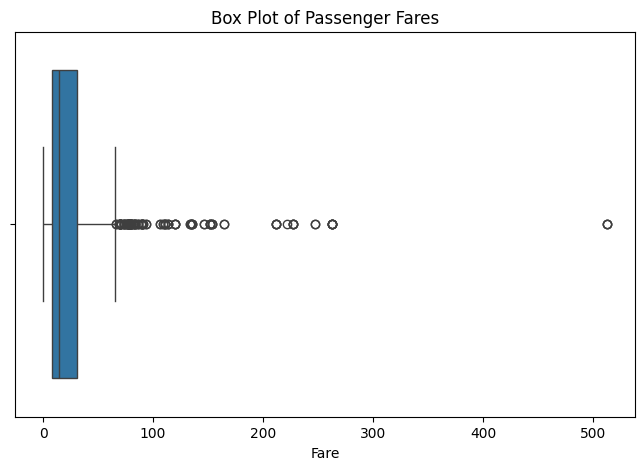

In [20]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df_clean["fare"])

plt.title("Box Plot of Passenger Fares")
plt.xlabel("Fare")

plt.show()

The box plot shows that most passenger fares are concentrated in the lower range. Several points appear beyond the upper whisker, indicating potential outliers. Some passengers paid significantly higher fares than others

In [21]:
# Convert Boolean column into integer
df_clean["alone"] = df_clean["alone"].astype(int)

# Apply One-Hot Encoding
df_encoded = pd.get_dummies(
    df_clean,
    columns=["sex", "embarked"],
    drop_first=True,
    dtype=int
)

# Display encoded dataset
print("Dataset After One-Hot Encoding:")
display(df_encoded.head())

print("\nEncoded Column Names:")
print(df_encoded.columns.tolist())

print("\nDataset Shape:", df_encoded.shape)

Dataset After One-Hot Encoding:


,survived,pclass,age,sibsp,parch,fare,alone,sex_male,embarked_Q,embarked_S
0,0,3,22.0,1,0,7.2500,0,1,0,1
1,1,1,38.0,1,0,71.2833,0,0,0,0
2,1,3,26.0,0,0,7.9250,1,0,0,1
3,1,1,35.0,1,0,53.1000,0,0,0,1
4,0,3,35.0,0,0,8.0500,1,1,0,1



Encoded Column Names:
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare', 'alone', 'sex_male', 'embarked_Q', 'embarked_S']

Dataset Shape: (891, 10)


In [22]:
from sklearn.preprocessing import StandardScaler

# Select numerical columns for scaling
features_to_scale = [
    "pclass",
    "age",
    "sibsp",
    "parch",
    "fare"
]

# Create StandardScaler object
scaler = StandardScaler()

# Apply feature scaling
df_encoded[features_to_scale] = scaler.fit_transform(
    df_encoded[features_to_scale]
)

print("Feature Scaling Completed Successfully!")

# Display scaled values
display(df_encoded[features_to_scale].head())

Feature Scaling Completed Successfully!


,pclass,age,sibsp,parch,fare
0,0.827377,-0.565736,0.432793,-0.473674,-0.502445
1,-1.566107,0.663861,0.432793,-0.473674,0.786845
2,0.827377,-0.258337,-0.474545,-0.473674,-0.488854
3,-1.566107,0.433312,0.432793,-0.473674,0.420730
4,0.827377,0.433312,-0.474545,-0.473674,-0.486337


In [23]:
# Check final dataset shape
print("Final Dataset Shape:", df_encoded.shape)

# Check missing values
print("\nTotal Missing Values:")
print(df_encoded.isnull().sum().sum())

# Check duplicate records
print("\nDuplicate Rows:")
print(df_encoded.duplicated().sum())

# Display final dataset
print("\nFinal Prepared Dataset:")
display(df_encoded.head(10))

Final Dataset Shape: (891, 10)

Total Missing Values:
0

Duplicate Rows:
116

Final Prepared Dataset:


,survived,pclass,age,sibsp,parch,fare,alone,sex_male,embarked_Q,embarked_S
0,0,0.827377,-0.565736,0.432793,-0.473674,-0.502445,0,1,0,1
1,1,-1.566107,0.663861,0.432793,-0.473674,0.786845,0,0,0,0
2,1,0.827377,-0.258337,-0.474545,-0.473674,-0.488854,1,0,0,1
3,1,-1.566107,0.433312,0.432793,-0.473674,0.420730,0,0,0,1
4,0,0.827377,0.433312,-0.474545,-0.473674,-0.486337,1,1,0,1
5,0,0.827377,-0.104637,-0.474545,-0.473674,-0.478116,1,1,1,0
6,0,-1.566107,1.893459,-0.474545,-0.473674,0.395814,1,1,0,1
7,0,0.827377,-2.102733,2.247470,0.767630,-0.224083,0,1,0,1
8,1,0.827377,-0.181487,-0.474545,2.008933,-0.424256,0,0,0,1
9,1,-0.369365,-1.180535,0.432793,-0.473674,-0.042956,0,0,0,0


In [24]:
# Save original dataset
df_original.to_csv("titanic_original.csv", index=False)

# Save final prepared dataset
df_encoded.to_csv(
    "prepared_titanic_dataset.csv",
    index=False
)

print("Both CSV files saved successfully!")

Both CSV files saved successfully!


In [25]:
from google.colab import files

files.download("prepared_titanic_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
files.download("titanic_original.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>